# 03 Top-5 test: Part A (build years only)
Build years = 1999-01-04 to 2020-12-31. **Nothing dated 2021 or later is loaded or computed here** (the file is filtered while reading).

Tests the dashboard's ranking idea, copied exactly:
- **Universe:** the 11 sector funds only, using those that exist on each checkpoint date (9 at the start, 10 from XLRE in 2015, 11 from XLC in 2018). A fund also needs a price 21 trading days before the checkpoint to be ranked. Industries and other markets are not included.
- **Past-month change** = close on the checkpoint / close 21 trading days earlier - 1. (Ranking by plain change or by change vs the sector average gives the same order.)
- **Checkpoints** every 21 trading days on the same grid as notebook 02 (every 21st trading day counted from 1999-01-04).
- **Main rule:** rank at the checkpoint close, **trade at the NEXT day's close**, hold equal weight until the next trade. Weights drift with prices between trades.
- **Top 5** = five highest past-month changes; **bottom 5** = five lowest (with only 9 funds the two groups share one fund). **Sector average** = equal weight of all sectors that exist that day, rebalanced daily, no cost (as in the locked settings).
- **Trading cost** = 0.10% of the amount traded: at each trade, cost = 0.001 x sum of absolute weight changes (drifted weights to new weights). The first purchase counts. The cost is taken out of the portfolio at the trade close, and counted in the holding period it pays for.
- **Holding period** = from one trade close to the next (about 21 trading days). A period's excess = top-5 return (after costs) minus the sector average's return over the same days. Only complete periods are used for period statistics; the last partial period (from the final trade to 2020-12-31) is kept in the growth, yearly and risk numbers.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import config
from rotation.data import load_prices, wide
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 300)
R = config.RESULTS_DIR; R.mkdir(exist_ok=True)
N = 21                              # checkpoint spacing (trading days) and main look-back
COST = config.COST_PER_TRADE        # 0.10% per unit traded
K = 5
SECT = config.SECTORS

## 1. Load build years only (sector funds, adjusted close)

In [2]:
df = load_prices(symbols=SECT, fields=["adj_close"], end=config.BUILD_END)
assert df.date.max() <= pd.Timestamp(config.BUILD_END)
P = wide(df, "adj_close")[SECT]
assert len(P) == 5536, len(P)       # same trading calendar as notebook 02
Rets = P.pct_change(fill_method=None)
avg_ret = Rets.mean(axis=1, skipna=True)                    # equal weight of sectors that exist that day, rebalanced daily
avg_idx = (1 + avg_ret.fillna(0)).cumprod()
print(P.index.min().date(), "to", P.index.max().date(), "|", len(P), "days | funds existing:",
      int(P.notna().sum(axis=1).min()), "to", int(P.notna().sum(axis=1).max()))

1999-01-04 to 2020-12-31 | 5536 days | funds existing: 9 to 11


## 2. The strategy engine
One function simulates day by day: drift the holdings, and at each trade close rebalance to equal weight on the chosen funds, paying 0.001 x sum of absolute weight changes.

In [3]:
def run_strategy(P, side="top", lookback=N, delay=1, k=K, cost=COST):
    Rt = P.pct_change(fill_method=None)
    n = len(P)
    checks = [i for i in range(N, n, N) if i >= lookback]                     # same grid as notebook 02
    trades = [(i, i + delay) for i in checks if i + delay <= n - 1]            # (rank position, trade position)
    trade_at = {t: i for i, t in trades}
    start = trades[0][1]
    hold = pd.Series(0.0, index=P.columns)
    wealth = pd.Series(np.nan, index=P.index)     # value after any trade that day (net of costs)
    before = pd.Series(np.nan, index=P.index)     # value just before trading
    log = []
    prev_set = None
    for d in range(start, n):
        if d > start:
            held = hold > 0
            assert not Rt.iloc[d][held].isna().any()
            hold = hold * (1 + Rt.iloc[d].fillna(0))
        v_before = hold.sum() if d > start else 1.0
        before.iloc[d] = v_before
        if d in trade_at:
            i = trade_at[d]
            chg = (P.iloc[i] / P.iloc[i - lookback] - 1).dropna()
            pick = chg.sort_values(ascending=(side == "bottom"), kind="mergesort").index[:k]
            w_new = pd.Series(0.0, index=P.columns); w_new[pick] = 1.0 / k
            w_old = hold / v_before if d > start else pd.Series(0.0, index=P.columns)
            turnover = (w_new - w_old).abs().sum()
            c = cost * turnover
            v_after = v_before * (1 - c)
            hold = v_after * w_new
            swaps = np.nan if prev_set is None else len(set(pick) - prev_set)
            log.append(dict(trade_date=P.index[d], rank_date=P.index[i], funds=" ".join(pick), n_ranked=len(chg),
                            turnover=turnover, cost_rate=c, swaps=swaps))
            prev_set = set(pick)
        wealth.iloc[d] = hold.sum()
        assert abs(hold.sum() - wealth.iloc[d]) < 1e-12 and (hold >= 0).all()
    log = pd.DataFrame(log)
    return dict(wealth=wealth, before=before, log=log, trades=trades, start=start)

def stat_wealth(res, idx_ref):
    """Wealth path for statistics: base 1.0 at the first trade close, costs show up in the following daily returns."""
    w = res["wealth"].copy(); w.iloc[res["start"]] = 1.0
    return w.iloc[res["start"]:]

def periods(res, avg_idx):
    t = [tp for _, tp in res["trades"]]
    rows = []
    for a, b in zip(t[:-1], t[1:]):
        net = res["before"].iloc[b] / res["before"].iloc[a] - 1       # includes the entry cost paid at trade a
        av = avg_idx.iloc[b] / avg_idx.iloc[a] - 1
        rows.append(dict(start=res["before"].index[a], end=res["before"].index[b], portfolio=net, average=av, excess=net - av))
    return pd.DataFrame(rows)

top = run_strategy(P, "top"); bot = run_strategy(P, "bottom")
assert top["start"] == bot["start"]
print("first trade (rank on", top["log"].rank_date.iloc[0].date(), ") at close", top["log"].trade_date.iloc[0].date(),
      "| trades:", len(top["log"]), "| ranked funds per check-in: min", top["log"].n_ranked.min(), "max", top["log"].n_ranked.max())
top["log"].head(3)

first trade (rank on 1999-02-03 ) at close 1999-02-04 | trades: 263 | ranked funds per check-in: min 9 max 11


,trade_date,rank_date,funds,n_ranked,turnover,cost_rate,swaps
0,1999-02-04,1999-02-03,XLK XLY XLV XLI XLF,9,1.000000,0.001000,NaN
1,1999-03-08,1999-03-05,XLF XLY XLE XLI XLV,9,0.404959,0.000405,1.0
2,1999-04-07,1999-04-06,XLK XLE XLI XLV XLY,9,0.412839,0.000413,1.0


## 3. Result 1: growth of $1, yearly return, ups and downs, worst drop
All start at the first trade close (1999-02-04) and end 2020-12-31. *Yearly return* = compound annual growth rate. *Ups and downs* = annualized standard deviation of daily returns. *Worst drop* = largest fall from a previous peak. Top 5 and bottom 5 are after costs; the sector average has no cost.

In [4]:
s0 = top["start"]
Wt, Wb = stat_wealth(top, avg_idx), stat_wealth(bot, avg_idx)
Wa = avg_idx.iloc[s0:] / avg_idx.iloc[s0]
def summarize(w):
    r = w.pct_change().dropna()
    years = (w.index[-1] - w.index[0]).days / 365.25
    dd = (w / w.cummax() - 1)
    return dict(total_growth_of_1=w.iloc[-1] / w.iloc[0], yearly_return_pct=((w.iloc[-1] / w.iloc[0]) ** (1 / years) - 1) * 100,
                ups_downs_pct=r.std() * np.sqrt(252) * 100, worst_drop_pct=dd.min() * 100, worst_drop_date=dd.idxmin().date())
summ = pd.DataFrame({"Top 5 (after costs)": summarize(Wt), "Bottom 5 (after costs)": summarize(Wb), "Sector average (no cost)": summarize(Wa)}).T
summ.insert(0, "start", Wt.index[0].date()); summ.insert(1, "end", Wt.index[-1].date())
summ.round(2).to_csv(R / "03_summary.csv")
summ.round(2)

,start,end,total_growth_of_1,yearly_return_pct,ups_downs_pct,worst_drop_pct,worst_drop_date
Top 5 (after costs),1999-02-04,2020-12-31,3.312613,5.619978,18.74795,-48.36925,2009-03-09
Bottom 5 (after costs),1999-02-04,2020-12-31,5.468037,8.06434,20.414063,-57.142006,2009-03-09
Sector average (no cost),1999-02-04,2020-12-31,5.587028,8.170594,18.857633,-52.53055,2009-03-09


## 4. Result 2: top 5 minus sector average, per holding period
Average excess per period, annualized (x12); share of periods the top 5 won; rough 95% range from resampling the holding periods (2,000 draws with replacement, fixed seed; treats periods as independent, so it is only a rough guide).

In [5]:
def excess_stats(per, seed=0, n_boot=2000):
    ex = per.excess.values
    rng = np.random.default_rng(seed)
    boots = np.array([ex[rng.integers(0, len(ex), len(ex))].mean() for _ in range(n_boot)]) * 12 * 100
    return dict(periods=len(ex), avg_excess_per_period_pct=ex.mean() * 100, annualized_excess_pct=ex.mean() * 12 * 100,
                share_periods_won_pct=(ex > 0).mean() * 100, range95_low_pct=np.percentile(boots, 2.5), range95_high_pct=np.percentile(boots, 97.5))
per_top, per_bot = periods(top, avg_idx), periods(bot, avg_idx)
ex_main = excess_stats(per_top)
pd.DataFrame({"Top 5 minus sector average": ex_main}).T.round(3)

,periods,avg_excess_per_period_pct,annualized_excess_pct,share_periods_won_pct,range95_low_pct,range95_high_pct
Top 5 minus sector average,262.0,-0.21,-2.524,42.748,-4.534,-0.546


In [6]:
pp = per_top.rename(columns={"portfolio": "top5_net", "average": "sector_average", "excess": "top5_minus_average"}).copy()
pp["bottom5_net"] = per_bot.portfolio.values
pp["bottom5_minus_average"] = pp.bottom5_net - pp.sector_average
pp.round(5).to_csv(R / "03_period_returns.csv", index=False)
print("periods:", len(pp), "| mean top5 per period %.3f%% | bottom5 %.3f%% | average %.3f%%" % (pp.top5_net.mean()*100, pp.bottom5_net.mean()*100, pp.sector_average.mean()*100))

periods: 262 | mean top5 per period 0.572% | bottom5 0.807% | average 0.782%


C:\Users\joyfu\AppData\Local\Temp\ipykernel_12464\3774174854.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  pp.round(5).to_csv(R / "03_period_returns.csv", index=False)


## 5. Result 3: year by year
Calendar-year returns of the after-cost wealth paths. 1999 starts at the first trade close (1999-02-04).

In [7]:
def yearly(w):
    ye = w.groupby(w.index.year).last()
    base = pd.concat([pd.Series([w.iloc[0]], index=[ye.index[0] - 1]), ye]).shift(1).iloc[1:]
    return (ye / base.values - 1) * 100
yr = pd.DataFrame({"top5_pct": yearly(Wt), "bottom5_pct": yearly(Wb), "sector_average_pct": yearly(Wa)})
yr["top5_minus_average"] = yr.top5_pct - yr.sector_average_pct
yr["bottom5_minus_average"] = yr.bottom5_pct - yr.sector_average_pct
yr.index.name = "year"
yr.round(2).to_csv(R / "03_by_year.csv")
print(yr.round(1).to_string())
print(f"\nyears top 5 beat the sector average: {(yr.top5_minus_average > 0).sum()} of {len(yr)}")
print(f"years bottom 5 beat the sector average: {(yr.bottom5_minus_average > 0).sum()} of {len(yr)}")
print(f"years top 5 beat bottom 5: {(yr.top5_pct > yr.bottom5_pct).sum()} of {len(yr)}")

      top5_pct  bottom5_pct  sector_average_pct  top5_minus_average  bottom5_minus_average
year                                                                                      
1999       9.5         21.4                15.7                -6.3                    5.6
2000      -5.9          4.1                 2.0                -7.9                    2.1
2001     -12.5         -2.7                -6.4                -6.1                    3.8
2002     -22.1        -14.5               -17.9                -4.2                    3.4
2003      20.6         35.6                28.6                -7.9                    7.1
2004      10.9         14.9                14.2                -3.4                    0.7
2005       7.8          5.3                 7.9                -0.0                   -2.6
2006       9.0         20.3                16.3                -7.3                    4.0
2007       3.9         13.1                 9.7                -5.7                    3.5

## 6. Result 4: trading costs and swaps
Cost per year = sum of the cost rates (% of portfolio value) over that year's trades. Swaps = how many of the five funds are new at each check-in (not counting the first purchase).

In [8]:
def cost_by_year(res):
    lg = res["log"].copy(); lg["year"] = lg.trade_date.dt.year
    return lg.groupby("year").agg(trades=("cost_rate", "size"), cost_pct_of_portfolio=("cost_rate", lambda s: s.sum() * 100))
cy = pd.concat({"top5": cost_by_year(top), "bottom5": cost_by_year(bot)}, axis=1)
cy.columns = [f"{a}_{b}" for a, b in cy.columns]
cy.round(3).to_csv(R / "03_costs_by_year.csv")
print(cy.round(3).to_string())
sw = pd.DataFrame({"top5": top["log"].swaps.describe(), "bottom5": bot["log"].swaps.describe()}).T
sw["share_with_0_swaps"] = [(top["log"].swaps.dropna() == 0).mean(), (bot["log"].swaps.dropna() == 0).mean()]
sw["avg_cost_per_trade_pct"] = [top["log"].cost_rate.iloc[1:].mean() * 100, bot["log"].cost_rate.iloc[1:].mean() * 100]
sw.round(3).to_csv(R / "03_swaps_summary.csv")
top["log"].round(6).to_csv(R / "03_trades_top5.csv", index=False); bot["log"].round(6).to_csv(R / "03_trades_bottom5.csv", index=False)
print("\nswaps per check-in (after the first purchase):"); print(sw.round(3).to_string())
print("average yearly cost drag (top 5): %.2f%% | (bottom 5): %.2f%%" % (cy.top5_cost_pct_of_portfolio.mean(), cy.bottom5_cost_pct_of_portfolio.mean()))

      top5_trades  top5_cost_pct_of_portfolio  bottom5_trades  bottom5_cost_pct_of_portfolio
year                                                                                        
1999           11                       0.983              11                          1.014
2000           12                       1.084              12                          1.127
2001           12                       1.205              12                          1.239
2002           12                       1.043              12                          1.202
2003           12                       1.242              12                          1.268
2004           12                       1.044              12                          0.980
2005           12                       0.965              12                          1.061
2006           12                       1.121              12                          0.984
2007           12                       1.042              12         


swaps per check-in (after the first purchase):
         count   mean    std  min  25%  50%  75%  max  share_with_0_swaps  avg_cost_per_trade_pct
top5     262.0  2.351  0.942  0.0  2.0  2.0  3.0  5.0               0.011                   0.094
bottom5  262.0  2.347  0.929  0.0  2.0  2.0  3.0  5.0               0.011                   0.096
average yearly cost drag (top 5): 1.13% | (bottom 5): 1.15%


C:\Users\joyfu\AppData\Local\Temp\ipykernel_12464\789137541.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  top["log"].round(6).to_csv(R / "03_trades_top5.csv", index=False); bot["log"].round(6).to_csv(R / "03_trades_bottom5.csv", index=False)
C:\Users\joyfu\AppData\Local\Temp\ipykernel_12464\789137541.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  top["log"].round(6).to_csv(R / "03_trades_top5.csv", index=False); bot["log"].round(6).to_csv(R / "03_trades_bottom5.csv", index=False)


## 7. Result 5: charts

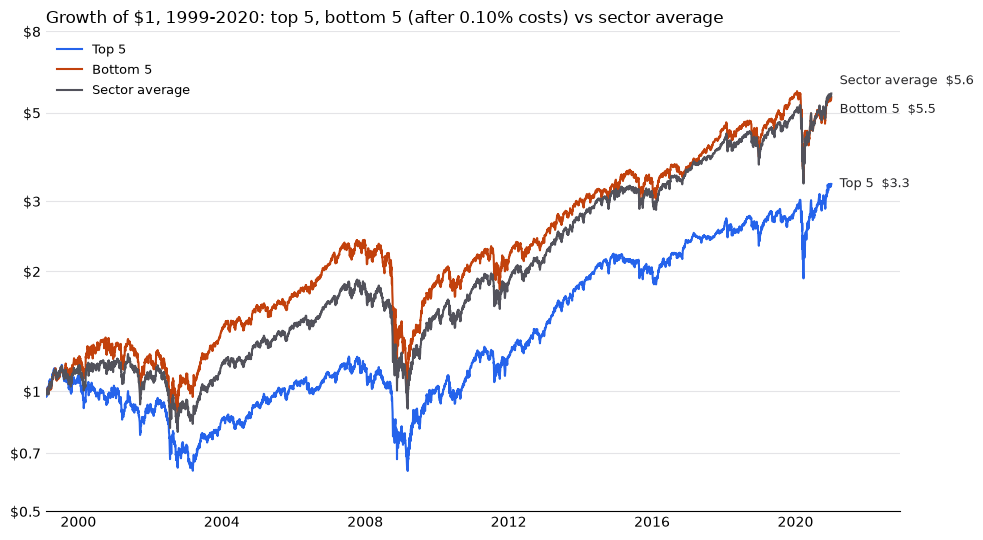

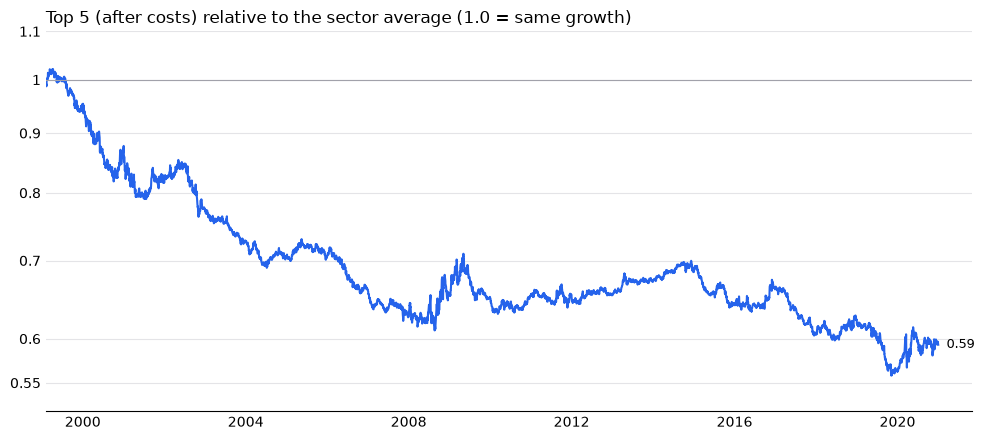

In [9]:
COL = {"Top 5": "#2563eb", "Bottom 5": "#c2410c", "Sector average": "#52525b"}
from matplotlib.ticker import NullFormatter, NullLocator
fig, ax = plt.subplots(figsize=(10, 5.5))
LABEL_DY = {"Top 5": 0, "Bottom 5": -9, "Sector average": 9}          # keeps the end labels from overlapping
for name, w in (("Top 5", Wt), ("Bottom 5", Wb), ("Sector average", Wa)):
    ax.plot(w.index, w, lw=1.5, color=COL[name], label=name)
    ax.annotate(f"{name}  ${w.iloc[-1]:.1f}", (w.index[-1], w.iloc[-1]), xytext=(6, LABEL_DY[name]), textcoords="offset points", va="center", fontsize=9, color="#27272a")
ax.set_yscale("log"); ax.set_yticks([0.5, 0.7, 1, 2, 3, 5, 8]); ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:g}"))
ax.yaxis.set_minor_locator(NullLocator()); ax.yaxis.set_minor_formatter(NullFormatter())
ax.grid(axis="y", color="#e4e4e7", lw=0.8); ax.set_axisbelow(True)
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
ax.tick_params(length=0); ax.set_xlim(Wt.index[0], Wt.index[-1] + pd.Timedelta(days=700))
ax.set_title("Growth of $1, 1999-2020: top 5, bottom 5 (after 0.10% costs) vs sector average", loc="left", fontsize=12)
ax.legend(frameon=False, loc="upper left", fontsize=9); fig.tight_layout()
fig.savefig(R / "03_growth_of_1.png", dpi=150); plt.show()

rel = Wt / Wa
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rel.index, rel, lw=1.5, color=COL["Top 5"]); ax.axhline(1, color="#a1a1aa", lw=0.8)
ax.set_yscale("log"); ax.set_yticks([0.55, 0.6, 0.7, 0.8, 0.9, 1, 1.1]); ax.set_ylim(0.52, 1.1)
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_locator(NullLocator()); ax.yaxis.set_minor_formatter(NullFormatter())
ax.grid(axis="y", color="#e4e4e7", lw=0.8); ax.set_axisbelow(True)
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
ax.tick_params(length=0)
ax.annotate(f"{rel.iloc[-1]:.2f}", (rel.index[-1], rel.iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_xlim(rel.index[0], rel.index[-1] + pd.Timedelta(days=300))
ax.set_title("Top 5 (after costs) relative to the sector average (1.0 = same growth)", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(R / "03_top5_relative_to_average.png", dpi=150); plt.show()

## 8. Information only (not judged against T1-T3)
(a) Rank by the 3-month change (63 trading days; same 21-day grid, so the first check-in is the 63rd trading day), trade next day. (b) Trade at the checkpoint close with no delay (1-month ranking). Result 2 for each, next to the main version.

In [10]:
variants = {"main: 1-month rank, trade next day": dict(lookback=N, delay=1),
            "(a) 3-month rank, trade next day": dict(lookback=63, delay=1),
            "(b) 1-month rank, no delay (trade at checkpoint close)": dict(lookback=N, delay=0)}
rows = {}
var_runs = {}
for name, kw in variants.items():
    rt = run_strategy(P, "top", **kw); var_runs[name] = rt
    st = excess_stats(periods(rt, avg_idx))
    st["first_trade"] = rt["log"].trade_date.iloc[0].date()
    st["avg_cost_per_trade_pct"] = rt["log"].cost_rate.iloc[1:].mean() * 100
    wv = stat_wealth(rt, avg_idx)
    st["top5_total_growth_of_1"] = wv.iloc[-1] / wv.iloc[0]
    wa_v = avg_idx.iloc[rt["start"]:] / avg_idx.iloc[rt["start"]]
    st["average_total_growth_of_1"] = wa_v.iloc[-1]
    rows[name] = st
var_tab = pd.DataFrame(rows).T
var_tab.round(3).to_csv(R / "03_variants_excess.csv")
assert abs(var_tab.loc["main: 1-month rank, trade next day", "annualized_excess_pct"] - ex_main["annualized_excess_pct"]) < 1e-9
var_tab.round(3)

,periods,avg_excess_per_period_pct,annualized_excess_pct,share_periods_won_pct,range95_low_pct,range95_high_pct,first_trade,avg_cost_per_trade_pct,top5_total_growth_of_1,average_total_growth_of_1
"main: 1-month rank, trade next day",262,-0.210338,-2.52406,42.748092,-4.534221,-0.546312,1999-02-04,0.094268,3.312613,5.587028
"(a) 3-month rank, trade next day",260,-0.180546,-2.166556,43.461538,-4.229812,-0.194501,1999-04-07,0.056945,3.525191,5.297795
"(b) 1-month rank, no delay (trade at checkpoint close)",262,-0.266156,-3.193877,40.076336,-5.174187,-1.199629,1999-02-03,0.094187,2.786713,5.553483


## 9. Checks for the three Part A predictions

In [11]:
ann = ex_main["annualized_excess_pct"]
print(f"T1: top-5 minus sector average = {ann:.2f}% per year after costs (average excess per period {ex_main['avg_excess_per_period_pct']:.3f}% x 12; need >= 1.0) -> {'CONFIRMED' if ann >= 1.0 else 'CONTRADICTED'}")
print(f"    rough 95% range from resampling periods: {ex_main['range95_low_pct']:.2f}% to {ex_main['range95_high_pct']:.2f}% per year ({ex_main['periods']} periods)")
wins = int((yr.top5_minus_average > 0).sum())
print(f"T2: top 5 beat the sector average in {wins} of {len(yr)} years (need >= 13) -> {'CONFIRMED' if wins >= 13 else 'CONTRADICTED'}")
share = ex_main["share_periods_won_pct"]
print(f"T3: top 5 beat the sector average in {share:.1f}% of {ex_main['periods']} holding periods (need > 50) -> {'CONFIRMED' if share > 50 else 'CONTRADICTED'}")
print()
print("Bottom 5 vs top 5: growth of $1 %.2f vs %.2f; yearly return %.2f%% vs %.2f%%" % (
    summ.loc['Bottom 5 (after costs)', 'total_growth_of_1'], summ.loc['Top 5 (after costs)', 'total_growth_of_1'],
    summ.loc['Bottom 5 (after costs)', 'yearly_return_pct'], summ.loc['Top 5 (after costs)', 'yearly_return_pct']))

T1: top-5 minus sector average = -2.52% per year after costs (average excess per period -0.210% x 12; need >= 1.0) -> CONTRADICTED
    rough 95% range from resampling periods: -4.53% to -0.55% per year (262 periods)
T2: top 5 beat the sector average in 8 of 22 years (need >= 13) -> CONTRADICTED
T3: top 5 beat the sector average in 42.7% of 262 holding periods (need > 50) -> CONTRADICTED

Bottom 5 vs top 5: growth of $1 5.47 vs 3.31; yearly return 8.06% vs 5.62%
